# 00 — Exploração dos dados negócio a negócio: WDO e WIN

**Objetivo:** antes de aplicar qualquer método do curso, entender os dados. As perguntas são:
- o que é um negócio;
- como o volume se distribui ao longo do dia;
- como são os retornos (caudas, autocorrelação);
- se o fluxo de agressão tem alguma relação com o preço no minuto seguinte.

Conceitos do curso usados aqui: **Cap. 2** ($Y = f(X) + \varepsilon$, predição × inferência) e uma prévia do **Cap. 3** (regressão linear).

**Pré-requisitos:**
```
python -m src.b3_download --dias 30   # baixa os .zip para data/raw/
python -m src.pipeline                # processa um pregão por vez para data/processed/
```

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.graphics.tsaplots import plot_acf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.pipeline import build, load
from src.features import add_forward_return

plt.rcParams["figure.figsize"] = (11, 4)
build()  # processa só os pregões novos de data/raw/

[]

## 1. Visão geral dos pregões
Cada pregão traz vários vencimentos. O pipeline fica só com o de maior volume (vencimento principal).

In [2]:
summary = load("summary").reset_index()
summary["root"] = summary["ticker"].str[:3]
por_dia = summary.pivot_table(index="day", columns="root", values=["negocios", "contratos"], aggfunc="sum")
print(f"{len(por_dia)} pregões: {por_dia.index.min()} a {por_dia.index.max()}")
por_dia.describe().loc[["mean", "min", "max"]].round(0)

20 pregões: 2026-10-20 a 2026-11-17


contratos               negocios           
root        WDO         WIN        WDO        WIN
mean  3090847.0  20225695.0   708189.0  6598529.0
min   1996720.0  12447691.0   444450.0  5001984.0
max   4700076.0  25371652.0  1097163.0  9345592.0

### O que é um negócio
Cada linha do arquivo é uma execução entre uma corretora compradora e uma vendedora. Uma ordem agressora grande "varre" várias ordens do livro e gera vários negócios no **mesmo milissegundo**. Por isso um negócio não é a mesma coisa que uma ordem.

In [3]:
from src.pipeline import PROCESSED_DIR

rows = []
for f in sorted((PROCESSED_DIR / "trades").glob("*.parquet")):
    t = pd.read_parquet(f, columns=["ts", "root", "qty"])
    for root, g in t.groupby("root", observed=True):
        rajada = g.groupby("ts").size()  # negócios por milissegundo
        rows.append({"dia": f.stem, "ativo": root, "negocios": len(g), "qty_1": (g["qty"] == 1).sum(),
                     "no_mesmo_ms": rajada[rajada > 1].sum(), "maior_rajada": rajada.max()})
neg = pd.DataFrame(rows)
tot = neg.groupby("ativo")[["negocios", "qty_1", "no_mesmo_ms"]].sum()
tot["% de 1 contrato"] = 100 * tot["qty_1"] / tot["negocios"]
tot["% no mesmo ms que outro"] = 100 * tot["no_mesmo_ms"] / tot["negocios"]
pico = neg.loc[neg.groupby("ativo")["maior_rajada"].idxmax()].set_index("ativo")
tot["maior rajada (negócios em 1 ms)"] = pico["maior_rajada"]
tot["dia da maior rajada"] = pico["dia"]
tot.drop(columns=["qty_1", "no_mesmo_ms"]).round(1)

,negocios,% de 1 contrato,% no mesmo ms que outro,maior rajada (negócios em 1 ms),dia da maior rajada
ativo,,,,,
WDO,13961004,67.3,80.3,1643,2026-11-05
WIN,131813261,59.1,77.0,4379,2026-11-05


### Tamanho dos negócios: contagem × volume

A coluna "% de 1 contrato" conta **negócios**: 1 contrato pesa o mesmo que um negócio de 500. Para saber de onde vem o volume, a tabela abaixo pondera cada negócio pelo número de contratos.

Lembrete: um negócio de 1 contrato não é uma ordem de 1 contrato. Uma compra a mercado de 20 contratos que encontra 20 ordens de 1 no livro vira 20 negócios de 1.

In [4]:
t = pd.concat([pd.read_parquet(f, columns=["root", "qty"]) for f in sorted((PROCESSED_DIR / "trades").glob("*.parquet"))])
tamanhos = {}
for root, g in t.groupby("root", observed=True):
    faixa = pd.cut(g["qty"], [0, 1, 5, 10, 50, np.inf], labels=["1", "2-5", "6-10", "11-50", "> 50"])
    tamanhos[(root, "% dos negócios")] = 100 * faixa.value_counts(normalize=True, sort=False)
    tamanhos[(root, "% do volume")] = 100 * g["qty"].groupby(faixa, observed=False).sum() / g["qty"].sum()
    print(f"{root}: média {g['qty'].mean():.1f} contratos por negócio, mediana {g['qty'].median():.0f}, "
          f"maior negócio {g['qty'].max():,}")
pd.DataFrame(tamanhos).rename_axis("contratos no negócio").round(1)

WDO: média 4.4 contratos por negócio, mediana 1, maior negócio 30,000


WIN: média 3.1 contratos por negócio, mediana 1, maior negócio 25,000


WDO                        WIN            
                     % dos negócios % do volume % dos negócios % do volume
contratos no negócio                                                      
1                              67.3        15.4           59.1        19.3
2-5                            18.6        12.9           28.5        28.8
6-10                            6.3        12.1            7.8        20.1
11-50                           7.0        37.6            4.5        26.7
> 50                            0.9        22.0            0.2         5.1

**O que os números mostram**
- Os negócios de 1 contrato são a maioria (67% no WDO e 59% no WIN), mas movimentam só 15–19% do volume.
- No **WDO**, o volume vem dos negócios grandes. Menos de 8% dos negócios (os de 11 contratos ou mais) carregam ~60% dos contratos.
- No **WIN**, o volume é mais espalhado entre os tamanhos.
- A média (4,4 e 3,1 contratos) fica bem acima da mediana (1): a distribuição do tamanho é muito assimétrica, com cauda longa.
- Os maiores negócios (dezenas de milhares de contratos num único negócio) provavelmente não são agressões no livro, e sim operações combinadas ou execuções de leilão. Isso ainda precisa ser verificado.

In [5]:
raw = load("bars_1min")
bars = {r: add_forward_return(g.drop(columns="root"), 1) for r, g in raw.groupby("root")}
bars["WDO"].head()

,open,high,low,close,volume,n_trades,signed_volume,vwap,imbalance,ret,fwd_ret_1
ts,,,,,,,,,,,
2026-10-20 09:00:00,5055.0,5056.5,5051.5,5053.5,6926,1601,-972,5054.289344,-0.140341,NaN,-0.003072
2026-10-20 09:01:00,5053.0,5053.5,5037.0,5038.0,26662,6738,-9196,5044.729334,-0.344910,-0.003072,0.000298
2026-10-20 09:02:00,5038.0,5041.0,5036.5,5039.5,16036,4595,506,5038.019799,0.031554,0.000298,0.000298
2026-10-20 09:03:00,5039.5,5042.0,5038.0,5041.0,9841,2828,2341,5040.124835,0.237882,0.000298,-0.000794
2026-10-20 09:04:00,5040.5,5041.5,5036.0,5037.0,11933,2835,-2101,5038.434719,-0.176066,-0.000794,-0.000993


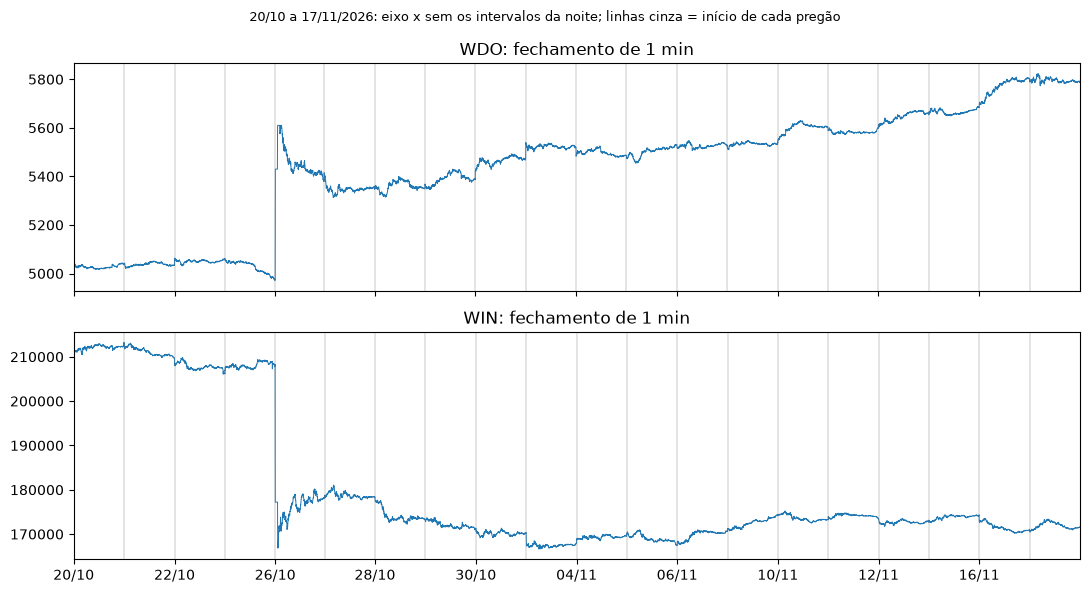

In [6]:
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
for ax, (root, b) in zip(axes, bars.items()):
    ax.plot(range(len(b)), b["close"].values, lw=0.7)
    day = b.index.normalize()
    starts = np.flatnonzero(day.to_series().diff().ne(pd.Timedelta(0)))
    for s in starts:
        ax.axvline(s, color="grey", lw=0.3)
    ax.set_xticks(starts[::2], [d.strftime("%d/%m") for d in day[starts][::2]])
    ax.set_xlim(0, len(b))
    ax.set_title(f"{root}: fechamento de 1 min")
axes[0].tick_params(labelbottom=False)
fig.suptitle("20/10 a 17/11/2026: eixo x sem os intervalos da noite; linhas cinza = início de cada pregão", fontsize=9)
plt.tight_layout()
fig.savefig(FIG / "precos_wdo_win.png", dpi=120)

## 2. Perfil intradiário do volume
A hipótese é um formato de "U", com mais volume na abertura e no fechamento.

Text(0.5, 1.0, 'Volume mediano por minuto do dia')

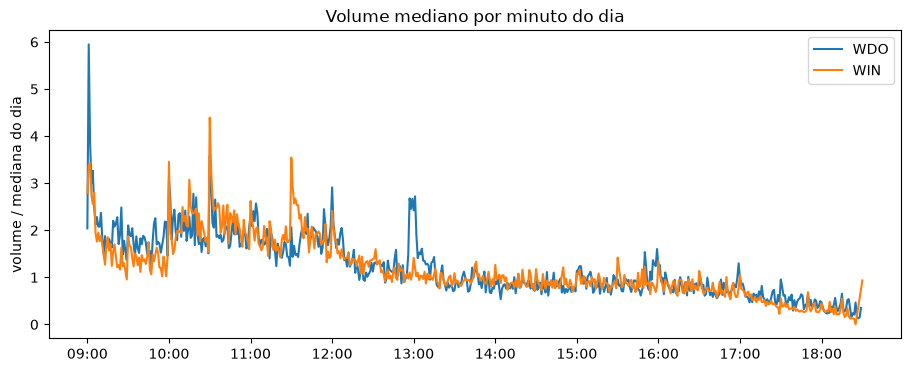

In [7]:
fig, ax = plt.subplots()
for root, b in bars.items():
    prof = b.groupby(b.index.strftime("%H:%M"))["volume"].median()
    ax.plot(prof.index, prof / prof.median(), label=root)
ax.set_xticks(ax.get_xticks()[::60]); ax.set_ylabel("volume / mediana do dia"); ax.legend()
ax.set_title("Volume mediano por minuto do dia")

In [8]:
faixas = [9, 9.5, 10, 12, 14, 16, 17.5, 18 + 35 / 60]
nomes = ["09:00-09:30", "09:30-10:00", "10:00-12:00", "12:00-14:00", "14:00-16:00", "16:00-17:30", "17:30-fim"]
minutos = pd.Series(np.diff(faixas) * 60, index=nomes)
tab = {}
for root, b in bars.items():
    faixa = pd.cut(b.index.hour + b.index.minute / 60, faixas, right=False, labels=nomes)
    vol = b["volume"].groupby([b.index.normalize(), faixa], observed=True).sum()
    share = vol / vol.groupby(level=0).transform("sum")            # fração do volume de cada dia
    pct = share.groupby(level=1, observed=True).mean() * 100        # média dos pregões, soma 100%
    intensidade = (pct / minutos) / (100 / minutos.sum())           # 1,0 = minuto médio do dia
    tab[(root, "% do volume do dia")] = pct.round(1)
    tab[(root, "intensidade (1,0 = média)")] = intensidade.round(2)
pd.DataFrame(tab).rename_axis("faixa de horário")  # a coluna "% do volume do dia" soma 100%

WDO                            \
                 % do volume do dia intensidade (1,0 = média)   
faixa de horário                                                
09:00-09:30                     9.2                      1.77   
09:30-10:00                     7.3                      1.40   
10:00-12:00                    32.4                      1.55   
12:00-14:00                    21.2                      1.02   
14:00-16:00                    15.3                      0.74   
16:00-17:30                    10.2                      0.65   
17:30-fim                       4.3                      0.38   

                                WIN                            
                 % do volume do dia intensidade (1,0 = média)  
faixa de horário                                               
09:00-09:30                     7.4                      1.42  
09:30-10:00                     6.1                      1.17  
10:00-12:00                    35.9                      1.72  
12:00-14:00                    20.8                      0.99  
14:00-16:00                    16.7                      0.80  
16:00-17:30                    10.1                      0.65  
17:30-fim                       3.0                      0.27

## 3. Distribuição dos retornos de 1 minuto
Retornos financeiros costumam ter **caudas gordas**, ou seja, curtose bem acima de 3 (o valor da normal).

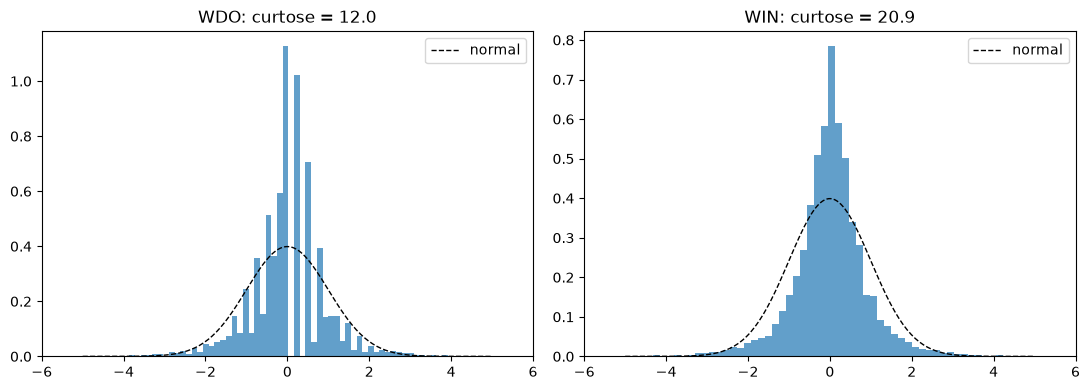

In [9]:
fig, axes = plt.subplots(1, 2)
for ax, (root, b) in zip(axes, bars.items()):
    r = b["ret"].dropna()
    ax.hist(r / r.std(), bins=150, density=True, alpha=0.7)
    x = np.linspace(-5, 5, 200); ax.plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), "k--", lw=1, label="normal")
    ax.set_xlim(-6, 6); ax.set_title(f"{root}: curtose = {r.kurt() + 3:.1f}"); ax.legend()
plt.tight_layout()

A assimetria e a curtose são sensíveis a poucos pontos extremos, então vale comparar com e sem 26/10.

In [10]:
def momentos(b):
    r = b["ret"].dropna()
    return pd.Series({"curtose": r.kurt() + 3, "assimetria": r.skew(), "n": len(r)})

sem_26 = {k: v[v.index.normalize() != "2026-10-26"] for k, v in bars.items()}
pd.concat({"todos os pregões": pd.DataFrame({k: momentos(v) for k, v in bars.items()}),
           "sem 26/10": pd.DataFrame({k: momentos(v) for k, v in sem_26.items()})}).round(2)

WDO       WIN
todos os pregões curtose        11.98     20.93
                 assimetria     -0.20     -0.05
                 n           11362.00  11256.00
sem 26/10        curtose        10.33     15.60
                 assimetria      0.02     -0.66
                 n           10811.00  10705.00

## 4. Autocorrelação
Uma autocorrelação negativa no lag 1 costuma vir do *bid-ask bounce*: o preço alterna entre negócios no bid e no ask.

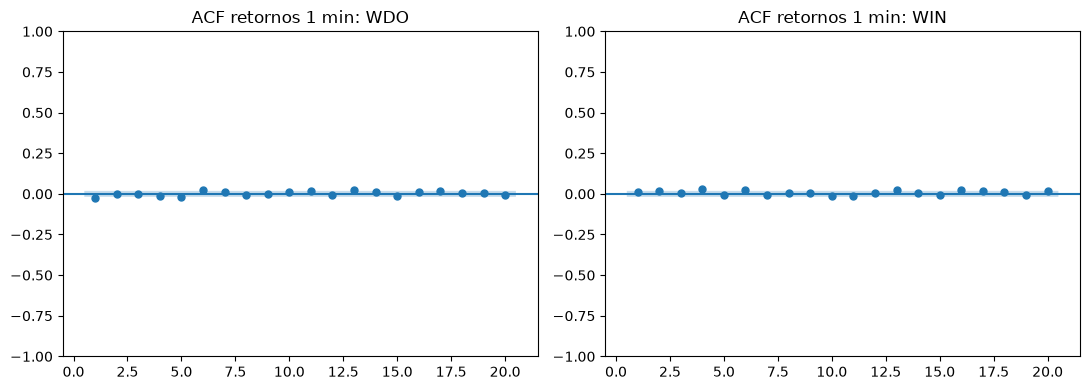

In [11]:
fig, axes = plt.subplots(1, 2)
for ax, (root, b) in zip(axes, bars.items()):
    plot_acf(b["ret"], missing="conservative", lags=20, ax=ax, title=f"ACF retornos 1 min: {root}", zero=False)
plt.tight_layout()

Duas autocorrelações diferentes:
- **ret:** a *direção* do minuto anterior ajuda a prever a do próximo?
- **|ret|:** a *intensidade* do movimento se repete? Se sim, a volatilidade se aglomera, com minutos agitados seguidos de minutos agitados.

Valores dentro da banda de 95% (±1,96/√n) não são distinguíveis de zero. **Cuidado:** essa banda supõe variância constante. Com a volatilidade aglomerada, que é justamente o que o |ret| mostra, ela fica estreita demais, e é o mesmo problema que o HAC corrige nas regressões (próxima célula).

O cálculo não emenda o último minuto de um pregão no primeiro do seguinte: os pares que atravessam a noite ou um leilão ficam de fora (`missing="conservative"`).

In [12]:
from statsmodels.tsa.stattools import acf

rows = []
for nome, conjunto in [("todos os pregões", bars), ("sem 26/10", sem_26)]:
    for root, b in conjunto.items():
        r = b["ret"]  # sem dropna: os NaN do início de cada trecho impedem emendar um pregão no outro
        a, a_abs = acf(r, nlags=3, missing="conservative"), acf(r.abs(), nlags=3, missing="conservative")
        rows.append({"amostra": nome, "ativo": root, "ret lag1": a[1], "ret lag2": a[2], "ret lag3": a[3],
                     "|ret| lag1": a_abs[1], "|ret| lag3": a_abs[3], "banda 95%": 1.96 / np.sqrt(r.notna().sum())})
pd.DataFrame(rows).set_index(["amostra", "ativo"]).round(3)

ret lag1  ret lag2  ret lag3  |ret| lag1  |ret| lag3  \
amostra          ativo                                                         
todos os pregões WDO      -0.025    -0.002    -0.003       0.288       0.253   
                 WIN       0.014     0.016     0.005       0.336       0.311   
sem 26/10        WDO      -0.035    -0.018    -0.006       0.206       0.176   
                 WIN      -0.024     0.003    -0.025       0.220       0.191   

                        banda 95%  
amostra          ativo             
todos os pregões WDO        0.018  
                 WIN        0.018  
sem 26/10        WDO        0.019  
                 WIN        0.019

Sem 26/10, o lag 1 do retorno fica fora da banda nos dois ativos. Para saber se isso é real, refazemos o mesmo teste como regressão (retorno do próximo minuto contra o deste) com dois erros-padrão: o comum, que supõe variância constante e erros independentes, e o HAC.

In [13]:
rows = []
for nome, conjunto in [("todos os pregões", bars), ("sem 26/10", sem_26)]:
    for root, b in conjunto.items():
        d = b[["ret", "fwd_ret_1"]].dropna() * 1e4
        comum = smf.ols("fwd_ret_1 ~ ret", d).fit()
        hac = smf.ols("fwd_ret_1 ~ ret", d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        rows.append({"amostra": nome, "ativo": root, "beta": comum.params["ret"], "t comum": comum.tvalues["ret"],
                     "t HAC": hac.tvalues["ret"], "R² (%)": 100 * comum.rsquared})
pd.DataFrame(rows).set_index(["amostra", "ativo"]).round(3)

beta  t comum  t HAC  R² (%)
amostra          ativo                               
todos os pregões WDO   -0.025   -2.661 -1.448   0.062
                 WIN    0.014    1.484  0.646   0.020
sem 26/10        WDO   -0.035   -3.745 -2.607   0.130
                 WIN   -0.024   -2.571 -1.293   0.062

**O que os números mostram**
- O HAC reduz o |t| pela metade, ou quase: sem 26/10, o do WDO vai de −3,7 para −2,6 e o do WIN de −2,6 para −1,3. A banda do ACF exagerava a significância.
- O que sobra no WDO é uma **reversão** pequena. Depois de um minuto de alta, o minuto seguinte devolve em média 3,5% do movimento, o que explica 0,13% da variância. É coerente com o *bid-ask bounce* (ver [glossário](../GLOSSARIO.md#bid-ask-bounce)).
- Economicamente, é irrelevante. Num minuto típico de ~3 bps, 3,5% dá ~0,1 bp, contra ~0,9 bp de 1 tick do WDO.

## 5. Fluxo de agressão → retorno seguinte (prévia do Cap. 3)
`imbalance` = (volume comprador − vendedor) / volume. O lado de cada negócio é estimado pela *tick rule*, porque o arquivo público não informa o agressor.

A correlação **no mesmo minuto** é quase mecânica: a tick rule usa o próprio preço. Para predição, o que interessa é o **minuto seguinte** (`fwd_ret_1`).
Os erros-padrão são HAC (Newey-West), robustos à autocorrelação e à heterocedasticidade que os retornos têm.

In [14]:
rows = []
for root, b in bars.items():
    d = b[["imbalance", "ret", "fwd_ret_1"]].dropna() * [1, 1e4, 1e4]  # retornos em bps
    same = smf.ols("ret ~ imbalance", d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    nxt = smf.ols("fwd_ret_1 ~ imbalance", d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    rows.append({"ativo": root, "n": len(d),
                 "mesmo min: beta (bps)": same.params["imbalance"], "mesmo min: t": same.tvalues["imbalance"], "mesmo min: R2": same.rsquared,
                 "próx. min: beta (bps)": nxt.params["imbalance"], "próx. min: t": nxt.tvalues["imbalance"], "próx. min: R2": nxt.rsquared})
pd.DataFrame(rows).set_index("ativo").round(4)

,n,mesmo min: beta (bps),mesmo min: t,mesmo min: R2,próx. min: beta (bps),próx. min: t,próx. min: R2
ativo,,,,,,,
WDO,11341,5.0165,44.3659,0.2458,-0.0113,-0.1431,0.0000
WIN,11235,23.0253,52.4932,0.3888,-0.4139,-1.5331,0.0001


## 6. WDO × WIN
Dólar e bolsa costumam andar em sentidos opostos: na fuga de risco, o dólar sobe e o índice cai. A pergunta é se essa relação se mantém estável de um dia para o outro.

corr(ret WDO, ret WIN) em 1 min, período todo = -0.461


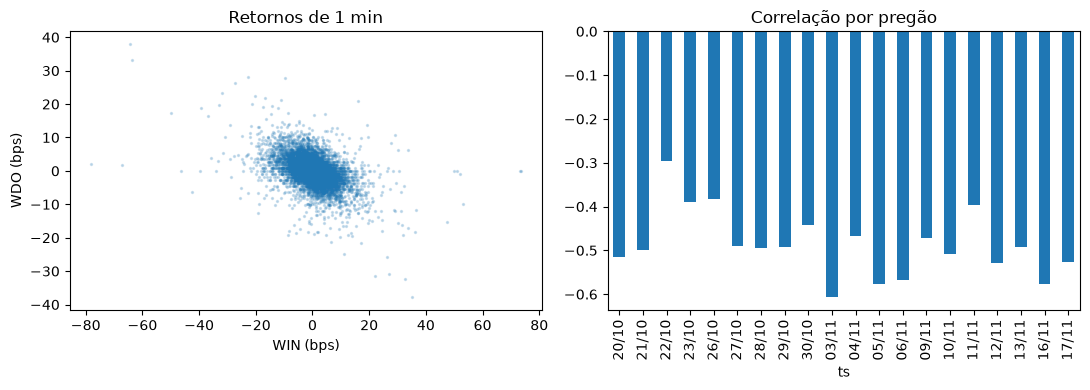

In [15]:
both = pd.concat({k: v["ret"] for k, v in bars.items()}, axis=1).dropna()
print(f"corr(ret WDO, ret WIN) em 1 min, período todo = {both.corr().iloc[0, 1]:+.3f}")
por_dia_corr = both.groupby(both.index.normalize()).apply(lambda g: g["WDO"].corr(g["WIN"]))
fig, axes = plt.subplots(1, 2)
axes[0].scatter(both["WIN"] * 1e4, both["WDO"] * 1e4, s=2, alpha=0.2); axes[0].set_xlabel("WIN (bps)"); axes[0].set_ylabel("WDO (bps)")
axes[0].set_title("Retornos de 1 min")
por_dia_corr.plot.bar(ax=axes[1], title="Correlação por pregão"); axes[1].set_xticklabels([d.strftime("%d/%m") for d in por_dia_corr.index])
plt.tight_layout()

### Um ativo antecipa o outro? E quantos testes fizemos?

Correlação no mesmo minuto não serve para prever. A pergunta útil é de **antecipação** (*lead-lag*): o retorno de um ativo agora ajuda a prever o do outro nos próximos minutos?

Para não olhar só o resultado mais bonito, a tabela abaixo registra **todos** os testes feitos: 2 ativos × 3 horizontes (1, 5 e 15 minutos à frente) × 3 preditores, num total de 18 regressões:
- `imbalance`: o fluxo de agressão do minuto;
- `ret`: o retorno do próprio ativo no minuto (continuação ou reversão);
- `ret_outro`: o retorno do **outro** ativo no minuto (antecipação).

Os retornos de 5 e 15 minutos se **sobrepõem**: o retorno de 9h00–9h05 e o de 9h01–9h06 compartilham 4 minutos. Isso cria autocorrelação nos erros por construção, e por isso o HAC usa `maxlags` = horizonte + 5.

Com 18 testes, |t| > 1,96 não basta. A **correção de Bonferroni** exige |t| > 2,99 para manter 5% de chance de *algum* falso positivo.

In [16]:
from scipy.stats import norm

testes = []
for root, b in bars.items():
    outro = "WIN" if root == "WDO" else "WDO"
    x = b[["close", "ret", "imbalance"]].join(bars[outro]["ret"].rename("ret_outro"))
    for h in [1, 5, 15]:
        x = add_forward_return(x, h)   # não atravessa pregões nem leilões
    for h in [1, 5, 15]:
        y = f"fwd_ret_{h}"
        for f in ["imbalance", "ret", "ret_outro"]:
            d = x[[y, f]].dropna()
            d[y] *= 1e4                                   # bps
            if f != "imbalance":
                d[f] *= 1e4
            m = smf.ols(f"{y} ~ {f}", d).fit(cov_type="HAC", cov_kwds={"maxlags": h + 5})
            testes.append({"ativo previsto": root, "horizonte (min)": h, "preditor": f, "beta": m.params[f],
                           "t": m.tvalues[f], "R² (%)": 100 * m.rsquared, "n": int(m.nobs)})
testes = pd.DataFrame(testes)
t_bonf = norm.ppf(1 - 0.05 / (2 * len(testes)))
testes["|t| > 1,96"] = testes["t"].abs() > 1.96
testes[f"|t| > {t_bonf:.2f} (Bonferroni)"] = testes["t"].abs() > t_bonf
print(f"{len(testes)} testes; limite de Bonferroni: |t| > {t_bonf:.2f}")
testes.round(3)

18 testes; limite de Bonferroni: |t| > 2.99


,ativo previsto,horizonte (min),preditor,beta,t,R² (%),n,"|t| > 1,96",|t| > 2.99 (Bonferroni)
0,WDO,1,imbalance,-0.007,-0.090,0.000,11362,False,False
1,WDO,1,ret,-0.025,-1.451,0.062,11341,False,False
2,WDO,1,ret_outro,0.001,0.136,0.000,11251,False,False
3,WDO,5,imbalance,-0.158,-0.616,0.005,11278,False,False
4,WDO,5,ret,-0.063,-1.897,0.086,11257,False,False
5,WDO,5,ret_outro,0.016,0.730,0.015,11246,False,False
6,WDO,15,imbalance,0.433,0.916,0.013,11068,False,False
7,WDO,15,ret,0.004,0.061,0.000,11047,False,False
8,WDO,15,ret_outro,-0.033,-0.702,0.020,11036,False,False
9,WIN,1,imbalance,-0.392,-1.455,0.011,11256,False,False


**O que os números mostram**
- Só 1 dos 18 testes passa de |t| > 1,96: o retorno do WDO "prevendo" o do WIN no minuto seguinte (t = −2,7). Com 18 testes e 5% de chance cada, o acaso sozinho produziria em média 0,9 "significativo". Então 1 é exatamente o esperado.
- Esse teste **não sobrevive** à correção de Bonferroni (|t| > 2,99). Não há evidência de que um ativo antecipe o outro em 1 a 15 minutos, nem de que o fluxo ou o próprio retorno prevejam os próximos minutos.
- Os R² ficam todos abaixo de 0,2%.
- Este é o tema do cap. 13 do ISLP (testes múltiplos), e o motivo de registrar *todos* os testes, não só o melhor.

## Conclusões

**Amostra:** 20 pregões, de 20/10 a 17/11/2026, com o vencimento principal de WDO e WIN e retornos em barras de 1 minuto.

**Visão geral da amostra:** o período tem um choque em 26/10, causado pelo resultado inesperado do segundo turno das eleições presidenciais ([CNN Brasil](https://www.cnnbrasil.com.br/blogs/lucinda-pinto/economia/money/mercado/vitoria-de-lula-surpreende-mercado-e-coloca-pesquisas-eleitorais-em-questao/), [g1](https://g1.globo.com/jornal-nacional/noticia/2026/10/26/mercado-financeiro-reage-a-vitoria-de-lula-com-queda-da-bolsa-de-valores-e-alta-do-dolar.ghtml)). Do fechamento de sexta para a abertura de segunda, o dólar subiu forte e o índice caiu forte (WDO +9,2%, WIN −14,9%). Depois disso, o dólar seguiu em alta e o índice ficou de lado em um patamar mais baixo. Os dois ativos se moveram em sentidos opostos também na escala de semanas.

**Negócio:** execução entre uma corretora compradora e uma vendedora. Uma ordem agressora gera vários negócios no mesmo milissegundo: cerca de 80% dos negócios dividem o milissegundo com outro, e a maior rajada chegou a 4.379 negócios do WIN em 1 ms (05/11). A maioria dos negócios é de 1 contrato (59% no WIN, 67% no WDO), mas eles movimentam só 15–19% do volume. No WDO, os negócios de 11 contratos ou mais são menos de 8% do total e carregam ~60% dos contratos.

**Volume:** concentrado na manhã, com pico na abertura no WDO e entre 10h e 12h no WIN. Cai ao longo da tarde e não tem formato de "U". Os horários de maior volume coincidem com os de maior volatilidade.

**Retornos:** caudas gordas (curtose 12 no WDO e 21 no WIN). A assimetria depende de 26/10. A direção quase não tem autocorrelação. Sem 26/10, o WDO mostra uma reversão pequena de um minuto para o outro, mas ela é estatisticamente frágil (t HAC = −2,6) e economicamente irrelevante (~0,1 bp, contra ~0,9 bp de 1 tick). A volatilidade se aglomera: a autocorrelação de |ret| fica entre 0,29 e 0,34 com todos os pregões e em ~0,2 sem 26/10. WDO e WIN têm correlação de −0,46 no mesmo minuto, sem um antecipar o outro: dos 18 testes registrados, só 1 passa de |t| > 1,96, e ele não sobrevive à correção de Bonferroni.

**Fluxo → preço:** forte no mesmo minuto, mas por construção da tick rule. Para o minuto seguinte, não há poder preditivo nesta amostra.